# Sensor-based time-series characterisation of chlorophyll-a (CHLO-206A, Raspberry Pi)


In [ ]:
import warnings; warnings.filterwarnings("ignore")
import os, json
from itertools import combinations
import numpy as np, pandas as pd
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import signal as sp, stats
from scipy.stats import norm
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score

# ------------------------------ CONFIG ------------------------------
XLSX = "chlorophyll_readings.xlsx"
TESTFILE = "device_test_records_2025-05-18.xlsx"
EXPECTED_TOTAL = 7242
CONTROLS = {"S12", "S13"}
DFA_SCALES = (4, 5, 6)
RQA_M, RQA_TAU, RQA_EPS = 3, 1, 0.20
SG_WINDOW, SG_POLY = 5, 2
SAX_W, SAX_A = 16, 5
BLOCK_LENGTHS = (60, 100, 150)
N_PERM, SEED = 2000, 42
# --------------------------------------------------------------------
os.makedirs("tables", exist_ok=True); os.makedirs("figures", exist_ok=True)
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
def savefig(name): plt.savefig(f"figures/{name}.png", bbox_inches="tight"); plt.show()

## 1. Data and acquisition summary (Table 3)

In [ ]:
df = pd.read_excel(XLSX, sheet_name="Sheet 1", usecols=["Site_ID","Time","Chl Temp (°C)","Chlorophyll (µg/L)"])
df.columns = ["Site","Time","temp","chl"]
df["Time"] = pd.to_datetime(df["Time"], errors="coerce")
df = df.dropna(subset=["chl"]).reset_index(drop=True)
assert len(df) == EXPECTED_TOTAL, len(df)
SITES = sorted(df.Site.unique(), key=lambda s: int(s.split("-")[0][1:]))
CODE = {s: s.split("-")[0] for s in SITES}
NAME = {CODE[s]: s.split("-",1)[1].strip() for s in SITES}
NAME = {c: ("Chlorella vulgaris (reference)" if "Chlorella" in n else n) for c, n in NAME.items()}
CODES = [CODE[s] for s in SITES]
INFER = [c for c in CODES if c not in CONTROLS]       # S1..S11
NATURAL = [c for c in INFER if c != "S11"]            # S1..S10
def frame(code): return df[df.Site == [s for s in SITES if CODE[s]==code][0]].reset_index(drop=True)

rows = []
for c in CODES:
    g = frame(c); d = g.Time.diff().dt.total_seconds().dropna()
    rows.append({"Sample": c, "Name": NAME[c], "N": len(g), "First": g.Time.min(), "Last": g.Time.max(),
                 "Duration (min)": round((g.Time.max()-g.Time.min()).total_seconds()/60, 1),
                 "Interval median (s)": d.median(), "Interval min (s)": d.min(), "Interval max (s)": d.max(),
                 "Backward steps": int((d<0).sum()),
                 "Mean Chl (µg/L)": round(g.chl.mean(),2), "SD Chl": round(g.chl.std(),2), "Mean T (°C)": round(g.temp.mean(),2)})
t3 = pd.DataFrame(rows)
assert (t3["Interval median (s)"] == 20).all(), "sampling interval is not 20 s"
assert (t3["Backward steps"] == 0).all(), "timestamps run backwards"
assert (t3["Interval min (s)"] == 20).all() and (t3["Interval max (s)"] == 20).all(), "gaps/overlaps present"
print(f"Total readings: {len(df)}  (mean {t3.N.mean():.0f} per sample, range {t3.N.min()}-{t3.N.max()})")
display(t3)

Total readings: 7242  (mean 557 per sample, range 450-648)


,Sample,Name,N,First,Last,Duration (min),Interval median (s),Interval min (s),Interval max (s),Backward steps,Mean Chl (µg/L),SD Chl,Mean T (°C)
0,S1,Ulhas River,556,2025-08-27 11:16:00,2025-08-27 14:21:00,185.0,20.0,20.0,20.0,0,48.31,7.61,28.41
1,S2,Kalu River,481,2025-08-27 18:19:00,2025-08-27 20:59:00,160.0,20.0,20.0,20.0,0,120.76,115.18,28.31
2,S3,Ambernath Lake,519,2025-08-30 12:03:00,2025-08-30 14:55:40,172.7,20.0,20.0,20.0,0,259.05,0.30,28.33
3,S4,Bhandup Lake,534,2025-08-30 17:41:20,2025-08-30 20:39:00,177.7,20.0,20.0,20.0,0,216.68,6.24,28.48
4,S5,Dhamapur Lake,648,2025-08-31 10:08:00,2025-08-31 13:43:40,215.7,20.0,20.0,20.0,0,191.07,5.29,28.43
5,S6,Shirpur Lake,561,2025-08-13 11:11:00,2025-08-13 14:17:40,186.7,20.0,20.0,20.0,0,232.07,6.19,28.38
6,S7,Varawade River,648,2025-08-28 13:58:00,2025-08-28 17:33:40,215.7,20.0,20.0,20.0,0,164.60,3.53,28.24
7,S8,Gotli River,644,2025-08-29 10:16:40,2025-08-29 13:51:00,214.3,20.0,20.0,20.0,0,224.85,3.38,28.09
8,S9,karli River,564,2025-08-31 17:31:40,2025-08-31 20:39:20,187.7,20.0,20.0,20.0,0,255.44,1.12,28.10
9,S10,Chivla River,632,2025-08-29 19:00:00,2025-08-29 22:30:20,210.3,20.0,20.0,20.0,0,202.47,1.11,28.26


## 2. Method implementations

In [ ]:
def prep(x):
    x = np.asarray(x, float)
    if len(x) >= SG_WINDOW: x = sp.savgol_filter(x, SG_WINDOW, SG_POLY)
    sd = x.std()
    return np.zeros_like(x) if sd < 1e-9 else (x - x.mean())/sd

def dfa_detail(x):
    Y = np.cumsum(x - x.mean()); F, Sc = [], []
    for s in DFA_SCALES:
        if len(Y) < 2*s: continue
        r = []
        for k in range(len(Y)//s):
            seg = Y[k*s:(k+1)*s]; t = np.arange(s)
            r.extend((seg - np.polyval(np.polyfit(t, seg, 1), t))**2)
        F.append(np.sqrt(np.mean(r))); Sc.append(s)
    if len(Sc) < 2 or min(F) <= 0: return np.nan, np.array(Sc), np.array(F), np.nan
    lx, ly = np.log(Sc), np.log(F); b = np.polyfit(lx, ly, 1)
    ss_res = np.sum((ly - np.polyval(b, lx))**2); ss_tot = np.sum((ly - ly.mean())**2)
    return float(b[0]), np.array(Sc), np.array(F), float(1 - ss_res/ss_tot) if ss_tot > 0 else np.nan
def dfa(x): return dfa_detail(x)[0]

def _runs(b):
    b = np.concatenate(([0], b.astype(np.int8), [0])); d = np.diff(b)
    return np.where(d == -1)[0] - np.where(d == 1)[0]

def recurrence_matrix(x):
    N = len(x) - (RQA_M-1)*RQA_TAU
    X = np.array([x[i:i+RQA_M*RQA_TAU:RQA_TAU] for i in range(N)])
    D = np.linalg.norm(X[:,None]-X[None,:], axis=2); mx = D.max()
    return (np.zeros_like(D, bool) if mx < 1e-9 else D <= RQA_EPS*mx)

def rqa(x, lmin=2, vmin=2):
    R = recurrence_matrix(x); N = R.shape[0]
    if not R.any(): return dict(RR=0.0, DET=0.0, ENTR=0.0, LAM=0.0)
    tot = R.sum(); dl = []
    for k in range(-(N-1), N):
        if k == 0: continue
        r = _runs(np.diag(R, k)); dl.extend(r[r >= lmin])
    vl = []
    for j in range(N):
        r = _runs(R[:, j]); vl.extend(r[r >= vmin])
    dl = np.array(dl)
    if len(dl): p = np.bincount(dl)/len(dl); p = p[p>0]; ent = float(-(p*np.log(p)).sum())
    else: ent = 0.0
    return dict(RR=tot/N**2, DET=dl.sum()/(tot+1e-9), ENTR=ent, LAM=np.sum(vl)/(tot+1e-9))

BP = norm.ppf(np.linspace(0, 1, SAX_A+1)[1:-1])
def paa(x, w=SAX_W):
    seg = len(x)/w; return np.array([x[int(j*seg):int((j+1)*seg)].mean() for j in range(w)])
def sax(x): return "".join("abcde"[np.searchsorted(BP, v)] for v in paa(x))

def autocorr(x, lag):
    xc = x - x.mean(); d = np.sum(xc**2)
    return np.sum(xc[:-lag]*xc[lag:])/d if d > 1e-9 else 0.0
def neff_multilag(x):
    x = np.asarray(x, float); n = len(x)
    if np.std(x) < 1e-9: return float(n), 0, 0.0
    thr = 1.96/np.sqrt(n); cum = 0.0; K = 0
    for lag in range(1, min(n//4, 150)+1):
        r = autocorr(x, lag)
        if abs(r) < thr: break
        cum += r; K = lag
    return max(n/(1+2*cum), 2.0), K, autocorr(x, 1)

In [ ]:
S = {}
for c in CODES:
    g = frame(c); x = g.chl.values.astype(float); t = g.temp.values.astype(float); z = prep(x)
    ne, K, r1 = neff_multilag(x)
    res = x - np.polyval(np.polyfit(t, x, 1), t) if (np.std(t) > 1e-9 and np.std(x) > 1e-9) else x - x.mean()
    za = prep(res)
    a, sc, F, r2 = dfa_detail(z)
    S[c] = dict(g=g, x=x, t=t, z=z, za=za, neff=ne, K=K, rho1=r1, alpha=a, dfa_sc=sc, dfa_F=F, dfa_r2=r2,
                alpha_adj=dfa(za), rqa=rqa(z), rqa_adj=rqa(za), sax=sax(z), sax_adj=sax(za))
print("Per-sample metrics computed for", len(S), "samples")

Per-sample metrics computed for 13 samples


## 3. DFA, RQA and SAX (Tables 4, 5, 9; Figures 7–10)

In [ ]:
rows4, rows5, rows9 = [], [], []
for c in CODES:
    s = S[c]; ctrl = c in CONTROLS
    rows4.append({"Sample": c, "Name": NAME[c],
                  "DFA alpha": np.nan if ctrl else round(s["alpha"],4),
                  "Log-log fit R2 (3 scales)": np.nan if ctrl else round(s["dfa_r2"],3),
                  "DFA alpha, temperature-adjusted": np.nan if ctrl else round(s["alpha_adj"],4),
                  "Note": "control: not estimable (below sensor resolution)" if ctrl else ""})
    q = s["rqa"]
    rows5.append({"Sample": c, "Name": NAME[c], **({k: np.nan for k in q} if ctrl else {k: round(v,4) for k,v in q.items()})})
    rows9.append({"Sample": c, "Name": NAME[c], "SAX word": "n/a (control)" if ctrl else s["sax"],
                  "SAX complexity": np.nan if ctrl else len(set(s["sax"]))/SAX_A})
t4, t5, t9 = pd.DataFrame(rows4), pd.DataFrame(rows5), pd.DataFrame(rows9)
print("Table 4 – DFA scaling exponent. R2 is the fit of log F(s) on log s over only three scales (4, 5, 6); treat alpha as a descriptive index.")
display(t4); print("Table 5 – RQA (m=3, tau=1, eps=0.20 x max distance)"); display(t5)
print("Table 9 – SAX (16 symbols, alphabet 5)"); display(t9)

Table 4 – DFA scaling exponent. R2 is the fit of log F(s) on log s over only three scales (4, 5, 6); treat alpha as a descriptive index.


,Sample,Name,DFA alpha,Log-log fit R2 (3 scales),"DFA alpha, temperature-adjusted",Note
0,S1,Ulhas River,1.8477,0.213,1.8246,
1,S2,Kalu River,1.8064,0.994,1.7752,
2,S3,Ambernath Lake,2.0597,0.993,2.1792,
3,S4,Bhandup Lake,-0.4721,0.143,0.5741,
4,S5,Dhamapur Lake,1.1557,0.287,1.1007,
5,S6,Shirpur Lake,1.5355,0.982,1.5190,
6,S7,Varawade River,0.9725,0.950,0.9416,
7,S8,Gotli River,1.9001,0.955,2.0672,
8,S9,karli River,-0.2085,0.014,1.2733,
9,S10,Chivla River,0.9396,0.315,1.0978,


Table 5 – RQA (m=3, tau=1, eps=0.20 x max distance)


,Sample,Name,RR,DET,ENTR,LAM
0,S1,Ulhas River,0.9471,0.9981,6.2775,1.0000
1,S2,Kalu River,0.5593,0.9962,4.4060,0.9999
2,S3,Ambernath Lake,0.3782,0.9827,3.0594,0.9919
3,S4,Bhandup Lake,0.3629,0.9938,4.5565,0.9994
4,S5,Dhamapur Lake,0.6970,0.9976,5.5251,0.9999
5,S6,Shirpur Lake,0.8150,0.9953,3.9730,0.9986
6,S7,Varawade River,0.9542,0.9983,5.0393,0.9999
7,S8,Gotli River,0.7440,0.9977,4.8513,0.9998
8,S9,karli River,0.4105,0.9929,3.9694,0.9988
9,S10,Chivla River,0.4340,0.9951,4.2876,0.9992


Table 9 – SAX (16 symbols, alphabet 5)


,Sample,Name,SAX word,SAX complexity
0,S1,Ulhas River,adddcccccddccccc,0.6
1,S2,Kalu River,eedbbbbbbbbbeecb,0.8
2,S3,Ambernath Lake,edbaedbaedbaedba,0.8
3,S4,Bhandup Lake,eeddcbaaeeddcbaa,1.0
4,S5,Dhamapur Lake,edcbbbbbeecbbbbb,0.8
5,S6,Shirpur Lake,beddcbaceddcbbbb,1.0
6,S7,Varawade River,ccccdcccdcccdccc,0.4
7,S8,Gotli River,adddadddadddbcdd,0.8
8,S9,karli River,edcbacedbbaeecba,1.0
9,S10,Chivla River,edcbadecbbaedcba,1.0


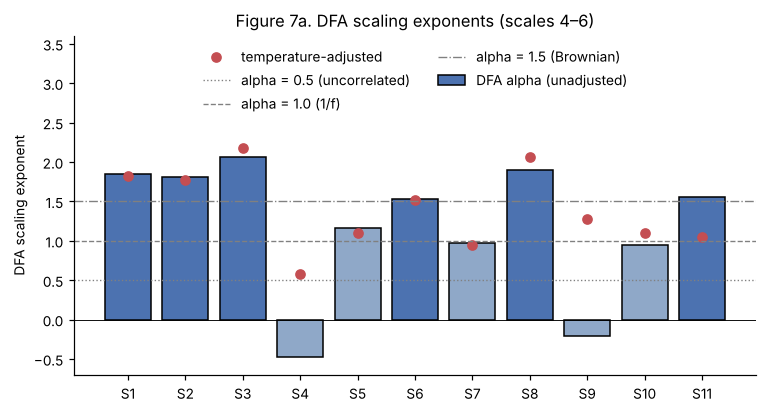

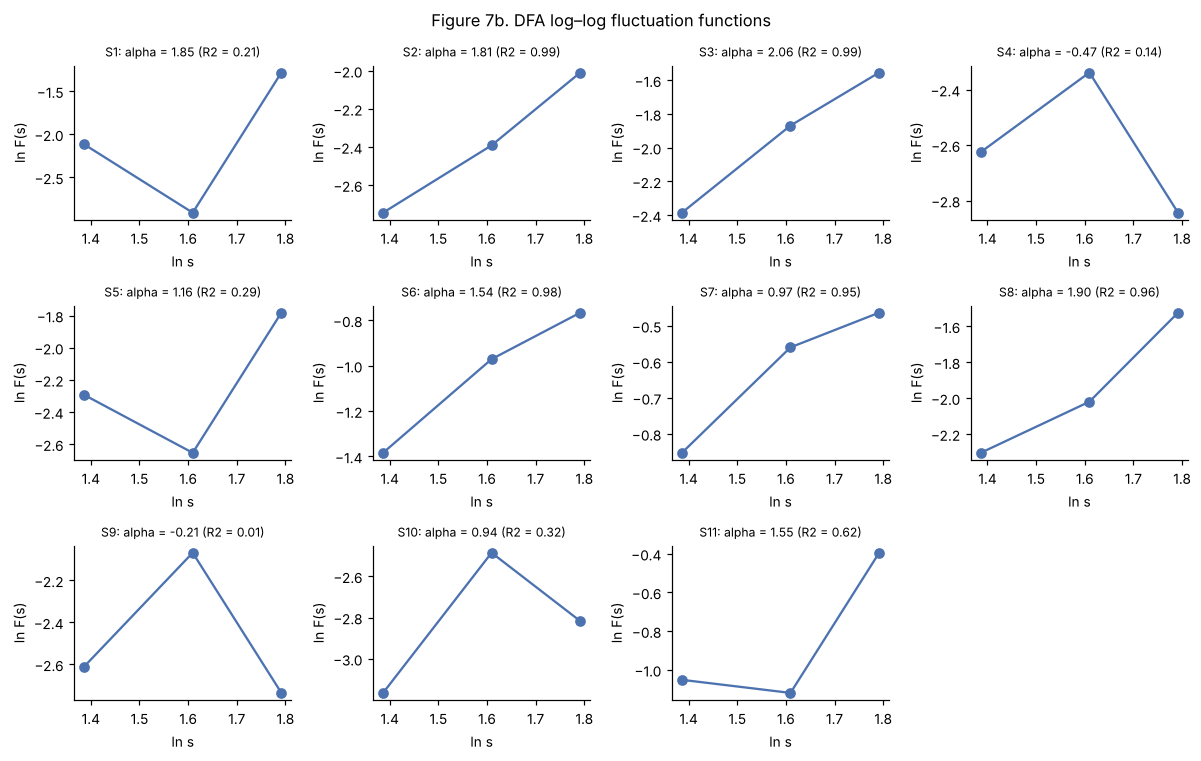

In [ ]:
# Figure 7a: DFA exponents
cols = ["#4C72B0" if S[c]["alpha"] >= 1.5 else "#8FA8C8" for c in INFER]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(INFER, [S[c]["alpha"] for c in INFER], color=cols, edgecolor="black", label="DFA alpha (unadjusted)")
ax.plot(INFER, [S[c]["alpha_adj"] for c in INFER], "o", color="#C44E52", label="temperature-adjusted")
for ref, ls, lab in ((0.5, ":", "alpha = 0.5 (uncorrelated)"), (1.0, "--", "alpha = 1.0 (1/f)"), (1.5, "-.", "alpha = 1.5 (Brownian)")):
    ax.axhline(ref, color="grey", ls=ls, lw=0.9, label=lab)
ax.axhline(0, color="black", lw=0.6)
ax.set_ylim(-0.7, 3.6); ax.set_ylabel("DFA scaling exponent"); ax.set_title("Figure 7a. DFA scaling exponents (scales 4–6)")
ax.legend(loc="upper center", ncol=2, frameon=False)
savefig("fig7a_dfa_alpha")

# Figure 7b: log-log fluctuation functions
fig, axs = plt.subplots(3, 4, figsize=(11, 7)); axs = axs.ravel()
for ax, c in zip(axs, INFER):
    s = S[c]; ax.plot(np.log(s["dfa_sc"]), np.log(s["dfa_F"]), "o-", color="#4C72B0")
    ax.set_title(f"{c}: alpha = {s['alpha']:.2f} (R2 = {s['dfa_r2']:.2f})", fontsize=8)
    ax.set_xlabel("ln s"); ax.set_ylabel("ln F(s)")
for ax in axs[len(INFER):]: ax.axis("off")
fig.suptitle("Figure 7b. DFA log–log fluctuation functions"); plt.tight_layout(); savefig("fig7b_dfa_loglog")

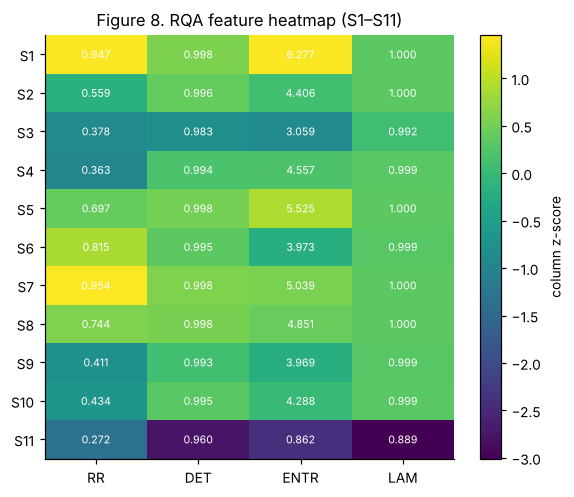

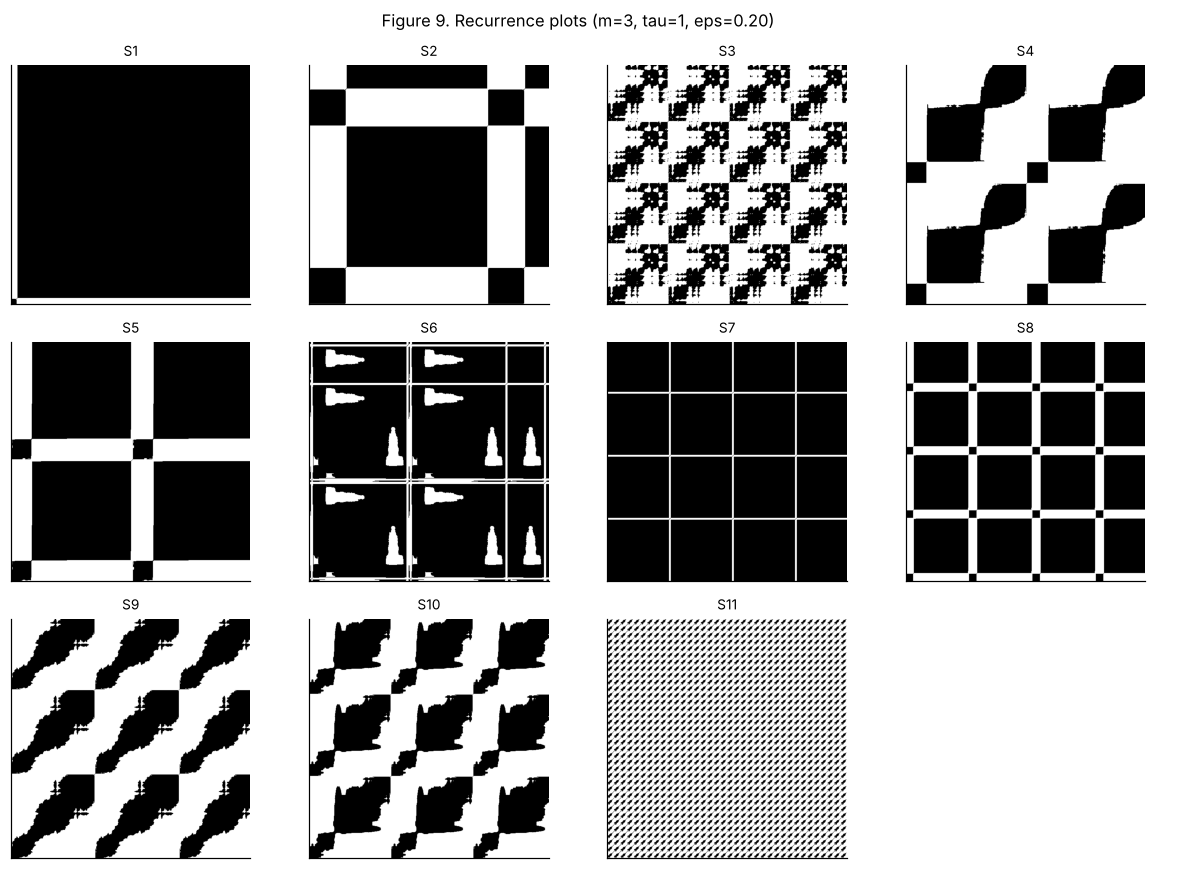

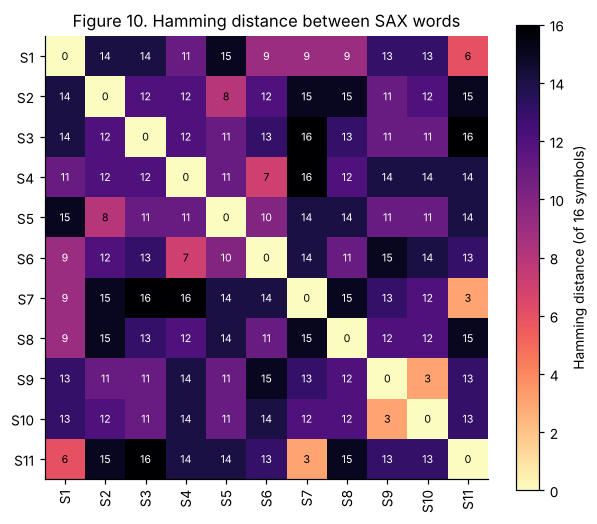

closest pairs: [('S7', 'S11', 3), ('S9', 'S10', 3), ('S1', 'S11', 6), ('S4', 'S6', 7), ('S2', 'S5', 8)]
most distant: [('S8', 'S11', 15), ('S2', 'S11', 15), ('S4', 'S7', 16), ('S3', 'S11', 16), ('S3', 'S7', 16)]
mean distance to others: {'S1': np.float64(11.3), 'S2': np.float64(12.6), 'S3': np.float64(12.9), 'S4': np.float64(12.3), 'S5': np.float64(11.9), 'S6': np.float64(11.8), 'S7': np.float64(12.7), 'S8': np.float64(12.8), 'S9': np.float64(11.6), 'S10': np.float64(11.5), 'S11': np.float64(12.2)}


In [ ]:
# Figure 8: RQA feature heatmap (annotated with raw values, colour = column-wise z-score)
M = pd.DataFrame({c: S[c]["rqa"] for c in INFER}).T[["RR","DET","ENTR","LAM"]]
Zs = (M - M.mean())/M.std()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(Zs.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(4)); ax.set_xticklabels(M.columns); ax.set_yticks(range(len(M))); ax.set_yticklabels(M.index)
for i in range(M.shape[0]):
    for j in range(4): ax.text(j, i, f"{M.values[i,j]:.3f}", ha="center", va="center", color="white", fontsize=7)
plt.colorbar(im, label="column z-score"); ax.set_title("Figure 8. RQA feature heatmap (S1–S11)"); savefig("fig8_rqa_heatmap")

# Figure 9: recurrence plots
fig, axs = plt.subplots(3, 4, figsize=(11, 8)); axs = axs.ravel()
for ax, c in zip(axs, INFER):
    ax.imshow(recurrence_matrix(S[c]["z"]), cmap="binary", origin="lower"); ax.set_title(c, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
for ax in axs[len(INFER):]: ax.axis("off")
fig.suptitle("Figure 9. Recurrence plots (m=3, tau=1, eps=0.20)"); plt.tight_layout(); savefig("fig9_recurrence_plots")

# Figure 10: Hamming distance matrix between SAX words
W = {c: S[c]["sax"] for c in INFER}
H = np.array([[sum(p != q for p, q in zip(W[u], W[v])) for v in INFER] for u in INFER])
fig, ax = plt.subplots(figsize=(6.5, 5.5)); im = ax.imshow(H, cmap="magma_r")
ax.set_xticks(range(len(INFER))); ax.set_xticklabels(INFER, rotation=90); ax.set_yticks(range(len(INFER))); ax.set_yticklabels(INFER)
for i in range(len(INFER)):
    for j in range(len(INFER)): ax.text(j, i, H[i,j], ha="center", va="center", fontsize=7, color="black" if H[i,j] < 9 else "white")
plt.colorbar(im, label="Hamming distance (of 16 symbols)"); ax.set_title("Figure 10. Hamming distance between SAX words")
savefig("fig10_sax_hamming")
Hd = pd.DataFrame(H, index=INFER, columns=INFER); Hd.to_csv("tables/hamming_matrix.csv")
iu = np.triu_indices(len(INFER), 1); order = np.argsort(H[iu])
print("closest pairs:", [(INFER[iu[0][i]], INFER[iu[1][i]], int(H[iu][i])) for i in order[:5]])
print("most distant:", [(INFER[iu[0][i]], INFER[iu[1][i]], int(H[iu][i])) for i in order[-5:]])
print("mean distance to others:", dict(zip(INFER, np.round(H.sum(1)/(len(INFER)-1), 1))))

## 4. Temperature (Tables 6, 7, 8)

In [ ]:
rows6 = []
for c in CODES:
    s = S[c]; t = s["t"]
    r, pr = (np.nan, np.nan) if c in CONTROLS else stats.pearsonr(t, s["x"])
    rows6.append({"Sample": c, "Name": NAME[c], "N": len(t), "T mean": round(t.mean(),2), "T SD": round(t.std(ddof=1),2),
                  "T min": round(t.min(),1), "T max": round(t.max(),1), "r (Chl vs T)": None if np.isnan(r) else round(r,2),
                  "p (raw N)": None if np.isnan(pr) else float(pr)})
t6 = pd.DataFrame(rows6); print("Table 6 – temperature during acquisition"); display(t6)

rows7 = []
for c in INFER:
    s = S[c]; r, p_raw = stats.pearsonr(s["t"], s["x"])
    ne = min(neff_multilag(s["t"])[0], neff_multilag(s["x"])[0]); dfe = max(ne-2, 1)
    tt = r*np.sqrt(dfe/(1-r**2+1e-12)); p_eff = 2*stats.t.sf(abs(tt), dfe)
    rows7.append({"Sample": c, "Name": NAME[c], "r": round(r,2), "N raw": len(s["x"]), "N eff": round(ne,1),
                  "p (raw N)": p_raw, "p (effective N)": p_eff, "Significant (eff. N)": bool(p_eff < 0.05)})
t7 = pd.DataFrame(rows7); print("Table 7 – Chl–temperature correlation with effective-N test"); display(t7)

rows8 = []
for c in INFER:
    s = S[c]
    rows8.append({"Sample": c, "Name": NAME[c], "DFA unadj": round(s["alpha"],4), "DFA adj": round(s["alpha_adj"],4),
                  "DET unadj": round(s["rqa"]["DET"],4), "DET adj": round(s["rqa_adj"]["DET"],4),
                  "SAX cx unadj": len(set(s["sax"]))/SAX_A, "SAX cx adj": len(set(s["sax_adj"]))/SAX_A})
t8 = pd.DataFrame(rows8); print("Table 8 – metrics before and after linear temperature adjustment"); display(t8)

Table 6 – temperature during acquisition


,Sample,Name,N,T mean,T SD,T min,T max,r (Chl vs T),p (raw N)
0,S1,Ulhas River,556,28.41,0.14,28.1,28.6,-0.07,1.154000e-01
1,S2,Kalu River,481,28.31,2.26,0.0,28.8,-0.01,8.738416e-01
2,S3,Ambernath Lake,519,28.33,0.18,28.0,28.6,-0.78,9.850966e-108
3,S4,Bhandup Lake,534,28.48,0.23,28.0,28.7,-0.87,3.556766e-162
4,S5,Dhamapur Lake,648,28.43,0.23,28.1,28.8,-0.58,3.929935e-60
5,S6,Shirpur Lake,561,28.38,0.17,27.8,28.6,-0.04,2.919341e-01
6,S7,Varawade River,648,28.24,0.22,27.8,28.6,-0.16,2.621300e-05
7,S8,Gotli River,644,28.09,0.09,27.9,28.3,0.43,4.421845e-30
8,S9,karli River,564,28.10,0.17,27.8,28.4,-0.92,3.546704e-234
9,S10,Chivla River,632,28.26,0.10,28.1,28.5,-0.77,7.482797e-124


Table 7 – Chl–temperature correlation with effective-N test


,Sample,Name,r,N raw,N eff,p (raw N),p (effective N),Significant (eff. N)
0,S1,Ulhas River,-0.07,556,9.9,1.154000e-01,8.549980e-01,False
1,S2,Kalu River,-0.01,481,8.5,8.738416e-01,9.858289e-01,False
2,S3,Ambernath Lake,-0.78,519,18.1,9.850966e-108,1.266028e-04,True
3,S4,Bhandup Lake,-0.87,534,8.3,3.556766e-162,4.295134e-03,True
4,S5,Dhamapur Lake,-0.58,648,7.0,3.929935e-60,1.701701e-01,False
5,S6,Shirpur Lake,-0.04,561,8.2,2.919341e-01,9.152862e-01,False
6,S7,Varawade River,-0.16,648,19.3,2.621300e-05,4.978540e-01,False
7,S8,Gotli River,0.43,644,19.4,4.421845e-30,6.446452e-02,False
8,S9,karli River,-0.92,564,13.4,3.546704e-234,4.691227e-06,True
9,S10,Chivla River,-0.77,632,15.5,7.482797e-124,6.469642e-04,True


Table 8 – metrics before and after linear temperature adjustment


,Sample,Name,DFA unadj,DFA adj,DET unadj,DET adj,SAX cx unadj,SAX cx adj
0,S1,Ulhas River,1.8477,1.8246,0.9981,0.9981,0.6,0.6
1,S2,Kalu River,1.8064,1.7752,0.9962,0.9962,0.8,0.8
2,S3,Ambernath Lake,2.0597,2.1792,0.9827,0.9731,0.8,0.6
3,S4,Bhandup Lake,-0.4721,0.5741,0.9938,0.9918,1.0,0.8
4,S5,Dhamapur Lake,1.1557,1.1007,0.9976,0.9945,0.8,1.0
5,S6,Shirpur Lake,1.5355,1.5190,0.9953,0.9951,1.0,0.8
6,S7,Varawade River,0.9725,0.9416,0.9983,0.9983,0.4,0.6
7,S8,Gotli River,1.9001,2.0672,0.9977,0.9889,0.8,1.0
8,S9,karli River,-0.2085,1.2733,0.9929,0.9705,1.0,1.0
9,S10,Chivla River,0.9396,1.0978,0.9951,0.9914,1.0,0.8


## 5. Effective sample size (Table 10)

In [ ]:
t10 = pd.DataFrame([{"Sample": c, "Name": NAME[c], "N raw": len(S[c]["x"]), "Lag cut-off K": S[c]["K"],
                     "rho lag-1": round(S[c]["rho1"],3), "N eff (multi-lag)": round(S[c]["neff"],1)} for c in INFER])
print("Table 10 – multi-lag effective sample size"); display(t10)

Table 10 – multi-lag effective sample size


,Sample,Name,N raw,Lag cut-off K,rho lag-1,N eff (multi-lag)
0,S1,Ulhas River,556,13,0.925,39.4
1,S2,Kalu River,481,52,0.983,8.5
2,S3,Ambernath Lake,519,29,0.905,18.1
3,S4,Bhandup Lake,534,56,0.976,9.4
4,S5,Dhamapur Lake,648,54,0.941,11.6
5,S6,Shirpur Lake,561,42,0.314,31.6
6,S7,Varawade River,648,0,-0.001,648.0
7,S8,Gotli River,644,18,0.952,32.9
8,S9,karli River,564,40,0.963,13.4
9,S10,Chivla River,632,42,0.969,15.6


## 6. Between-sample inference (Welch, Levene, Kruskal–Wallis, Games–Howell, block permutation; Figure 12)

In [ ]:
groups = {c: S[c]["x"] for c in INFER}; k = len(INFER)
means = np.array([groups[c].mean() for c in INFER]); vars_ = np.array([groups[c].var(ddof=1) for c in INFER])
ns = np.array([len(groups[c]) for c in INFER], float); nes = np.array([S[c]["neff"] for c in INFER])

def welch(n_use):
    w = n_use/vars_; gm = (w*means).sum()/w.sum(); num = (w*(means-gm)**2).sum()/(k-1)
    term = ((1-w/w.sum())**2/(n_use-1)).sum(); F = num/(1+2*(k-2)/(k**2-1)*term); df2 = (k**2-1)/(3*term)
    return F, k-1, df2, stats.f.sf(F, k-1, df2)
inf = {"welch_effN": welch(nes), "welch_rawN": welch(ns)}
lev = stats.levene(*groups.values(), center="mean"); bf = stats.levene(*groups.values(), center="median")
inf["levene"] = (lev.statistic, lev.pvalue); inf["brown_forsythe"] = (bf.statistic, bf.pvalue)
kw = stats.kruskal(*groups.values()); ntot = int(ns.sum())
inf["kruskal"] = (kw.statistic, k-1, kw.pvalue, (kw.statistic-k+1)/(ntot-k))

gh = []
for i, j in combinations(range(k), 2):
    va, vb = vars_[i]/nes[i], vars_[j]/nes[j]; se2 = va+vb; diff = means[i]-means[j]
    dfw = se2**2/(va**2/(nes[i]-1)+vb**2/(nes[j]-1))
    q = abs(diff)/np.sqrt(se2/2); p = stats.studentized_range.sf(q, k, dfw)
    half = stats.studentized_range.ppf(0.95, k, dfw)*np.sqrt(se2/2)
    sp_ = np.sqrt(((ns[i]-1)*vars_[i]+(ns[j]-1)*vars_[j])/(ns[i]+ns[j]-2))
    g_ = diff/sp_*(1-3/(4*(ns[i]+ns[j])-9))
    gh.append({"A": INFER[i], "B": INFER[j], "mean diff": diff, "CI95 low": diff-half, "CI95 high": diff+half, "p (eff. N)": p, "Hedges g": g_})
gh = pd.DataFrame(gh); sig = gh[gh["p (eff. N)"] < 0.05]
ag = sig["Hedges g"].abs()
inf["gh_sig"] = (len(sig), len(gh)); inf["gh_nonsig"] = gh[gh["p (eff. N)"] >= 0.05][["A","B"]].values.tolist()
inf["gh_g"] = (ag.median(), ag.quantile(.25), ag.quantile(.75), ag.min())

def chunks(x, L): return np.array_split(x, max(1, len(x)//L))
perm = {}; Fobs = welch(ns)[0]
for L in BLOCK_LENGTHS:
    per = [chunks(groups[c], L) for c in INFER]; counts = [len(p) for p in per]; pool = [b for p in per for b in p]; null = np.empty(N_PERM)
    for i in range(N_PERM):
        idx = rng.permutation(len(pool)); pos = 0; gs = []
        for cnt in counts: gs.append(np.concatenate([pool[j] for j in idx[pos:pos+cnt]])); pos += cnt
        m = np.array([a.mean() for a in gs]); v = np.array([a.var(ddof=1) for a in gs]); n_ = np.array([len(a) for a in gs], float)
        w = n_/v; gm = (w*m).sum()/w.sum(); num = (w*(m-gm)**2).sum()/(k-1)
        term = ((1-w/w.sum())**2/(n_-1)).sum(); null[i] = num/(1+2*(k-2)/(k**2-1)*term)
    perm[L] = dict(blocks=len(pool), null_max=float(null.max()), p=float(((null >= Fobs).sum()+1)/(N_PERM+1)))
inf["perm"] = perm

F, d1, d2, p = inf["welch_effN"]
print(f"Welch (effective N): F = {F:.3g}, df = ({d1}, {d2:.1f}), p = {p:.2g}   [raw-N F = {inf['welch_rawN'][0]:.3g}]")
print(f"Levene W = {lev.statistic:.0f} (p = {lev.pvalue:.2g});  Brown-Forsythe W = {bf.statistic:.0f} (p = {bf.pvalue:.2g})")
print(f"Kruskal-Wallis H = {kw.statistic:.1f}, df = {k-1}, p = {kw.pvalue:.2g}, epsilon^2 = {inf['kruskal'][3]:.2f}")
print(f"Games-Howell (eff. N): {len(sig)}/{len(gh)} pairs significant; non-significant: {inf['gh_nonsig']}")
print(f"|Hedges g| among significant pairs: median {ag.median():.1f} (IQR {ag.quantile(.25):.1f}-{ag.quantile(.75):.1f}), min {ag.min():.1f}")
print(f"Total N raw = {int(ns.sum())}, total N effective = {nes.sum():.0f}")
print("Block permutation (observed raw-N Welch F = %.3g):" % Fobs)
for L, r in perm.items(): print(f"  block {L:>3}: {r['blocks']} blocks, null max F = {r['null_max']:.0f}, p = {r['p']:.4f} (floor 1/{N_PERM+1})")
display(gh.round(4))

Welch (effective N): F = 1.12e+05, df = (10, 68.0), p = 3e-139   [raw-N F = 4.6e+05]
Levene W = 2976 (p = 0);  Brown-Forsythe W = 248 (p = 0)
Kruskal-Wallis H = 5104.9, df = 10, p = 0, epsilon^2 = 0.81
Games-Howell (eff. N): 44/55 pairs significant; non-significant: [['S1', 'S2'], ['S2', 'S3'], ['S2', 'S4'], ['S2', 'S5'], ['S2', 'S6'], ['S2', 'S7'], ['S2', 'S8'], ['S2', 'S9'], ['S2', 'S10'], ['S2', 'S11'], ['S4', 'S8']]
|Hedges g| among significant pairs: median 16.8 (IQR 7.5-29.6), min 1.5
Total N raw = 6327, total N effective = 1135
Block permutation (observed raw-N Welch F = 4.6e+05):
  block  60: 100 blocks, null max F = 536, p = 0.0005 (floor 1/2001)
  block 100: 58 blocks, null max F = 1312, p = 0.0005 (floor 1/2001)
  block 150: 37 blocks, null max F = 23610, p = 0.0005 (floor 1/2001)


,A,B,mean diff,CI95 low,CI95 high,p (eff. N),Hedges g
0,S1,S2,-72.4540,-245.3079,100.3998,0.7416,-0.9207
1,S1,S3,-210.7412,-214.8941,-206.5883,0.0000,-38.4309
2,S1,S4,-168.3789,-177.2382,-159.5196,0.0000,-24.1275
3,S1,S5,-142.7669,-149.7238,-135.8100,0.0000,-22.0637
4,S1,S6,-183.7606,-189.2157,-178.3054,0.0000,-26.4776
5,S1,S7,-116.2951,-120.4632,-112.1270,0.0000,-20.0927
6,S1,S8,-176.5414,-181.0690,-172.0137,0.0000,-30.7262
7,S1,S9,-207.1329,-211.3829,-202.8829,0.0000,-38.1701
8,S1,S10,-154.1674,-158.4013,-149.9335,0.0000,-29.2298
9,S1,S11,-62.7748,-66.9399,-58.6096,0.0000,-11.1082


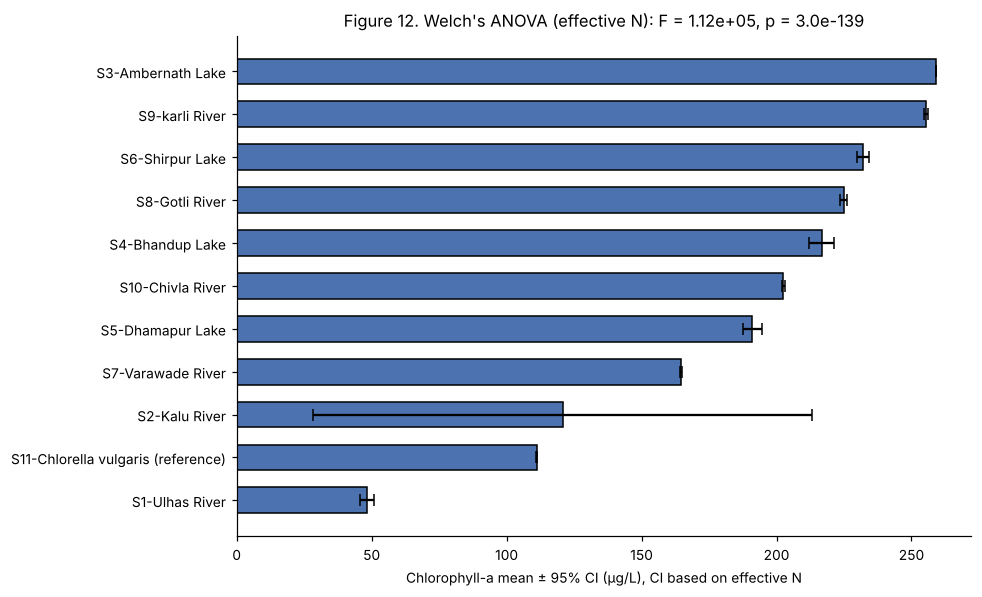

,label,mean,neff,ci
0,S1-Ulhas River,48.31,39.39,2.45
1,S11-Chlorella vulgaris (reference),111.08,306.46,0.25
2,S2-Kalu River,120.76,8.47,92.43
3,S7-Varawade River,164.60,648.00,0.27
4,S5-Dhamapur Lake,191.07,11.60,3.43
5,S10-Chivla River,202.47,15.58,0.60
6,S4-Bhandup Lake,216.68,9.45,4.64
7,S8-Gotli River,224.85,32.85,1.20
8,S6-Shirpur Lake,232.07,31.58,2.25
9,S9-karli River,255.44,13.44,0.66


In [ ]:
# Figure 12: mean +/- 95% CI using effective N
d = pd.DataFrame({"code": INFER, "mean": means, "sd": np.sqrt(vars_), "neff": nes})
d["ci"] = [stats.t.ppf(0.975, max(n-1,1))*s/np.sqrt(n) for s, n in zip(d.sd, d.neff)]
d["label"] = [f"{c}-{NAME[c]}" for c in d.code]; d = d.sort_values("mean").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 5.5)); y = np.arange(len(d))
ax.barh(y, d["mean"], xerr=d["ci"], color="#4C72B0", edgecolor="black", height=0.6, capsize=4)
ax.set_yticks(y); ax.set_yticklabels(d["label"]); ax.set_xlabel("Chlorophyll-a mean ± 95% CI (µg/L), CI based on effective N")
ax.set_title(f"Figure 12. Welch's ANOVA (effective N): F = {F:.2e}, p = {p:.1e}")
plt.tight_layout(); savefig("fig12_means_ci")
display(d[["label","mean","neff","ci"]].round(2))

## 7. Clustering (Table 11; Figures 11 and 13)

Table 11 – clustering validity (features: alpha, RR, DET, ENTR, LAM, SAX complexity; Ward)


,Sample set,n,k,Silhouette,Davies-Bouldin,Cluster sizes,Assignment
0,S1-S11 (natural + Chlorella),11,2,0.558,0.265,10/1,S1:0 S2:0 S3:0 S4:0 S5:0 S6:0 S7:0 S8:0 S9:0 S...
1,S1-S11 (natural + Chlorella),11,3,0.329,0.609,7/1/3,S1:0 S2:0 S3:0 S4:2 S5:0 S6:0 S7:0 S8:0 S9:2 S...
2,S1-S11 (natural + Chlorella),11,4,0.304,0.668,5/2/3/1,S1:1 S2:0 S3:0 S4:2 S5:0 S6:0 S7:1 S8:0 S9:2 S...
3,S1-S10 (natural only),10,2,0.321,1.101,4/6,S1:1 S2:1 S3:0 S4:0 S5:1 S6:1 S7:1 S8:1 S9:0 S...
4,S1-S10 (natural only),10,3,0.349,0.582,6/3/1,S1:0 S2:0 S3:2 S4:1 S5:0 S6:0 S7:0 S8:0 S9:1 S...
5,S1-S10 (natural only),10,4,0.327,0.633,4/2/1/3,S1:1 S2:0 S3:2 S4:3 S5:0 S6:0 S7:1 S8:0 S9:3 S...


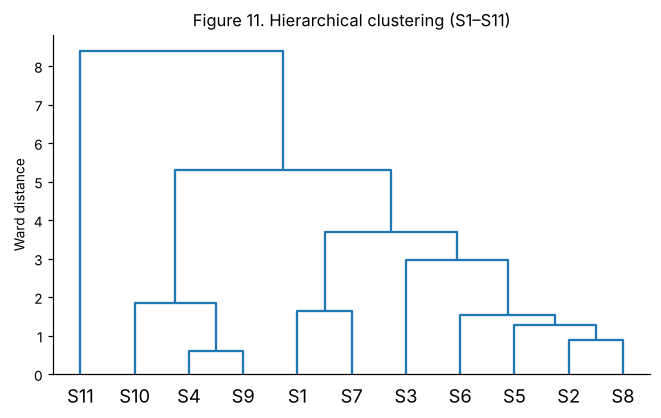

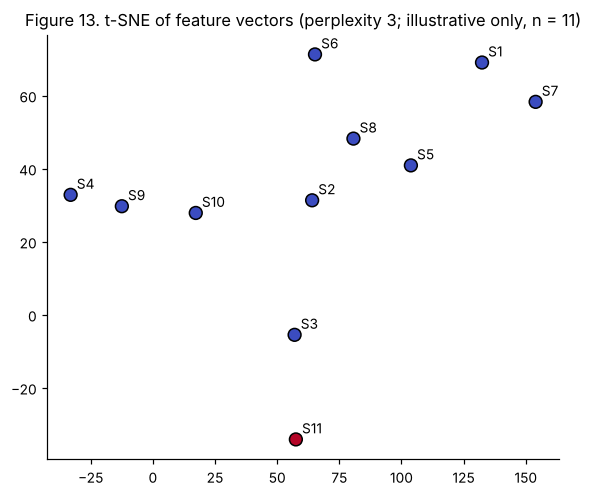

In [ ]:
def feats(codes):
    rows = []
    for c in codes:
        s = S[c]; q = s["rqa"]; rows.append([s["alpha"], q["RR"], q["DET"], q["ENTR"], q["LAM"], len(set(s["sax"]))/SAX_A])
    return StandardScaler().fit_transform(np.array(rows))
clu = []
for label, codes in (("S1-S11 (natural + Chlorella)", INFER), ("S1-S10 (natural only)", NATURAL)):
    X = feats(codes)
    for kk in (2, 3, 4):
        lab = AgglomerativeClustering(n_clusters=kk, linkage="ward").fit_predict(X)
        clu.append({"Sample set": label, "n": len(codes), "k": kk, "Silhouette": round(silhouette_score(X, lab),3),
                    "Davies-Bouldin": round(davies_bouldin_score(X, lab),3), "Cluster sizes": "/".join(map(str, np.bincount(lab))),
                    "Assignment": " ".join(f"{c}:{l}" for c, l in zip(codes, lab))})
t11 = pd.DataFrame(clu); print("Table 11 – clustering validity (features: alpha, RR, DET, ENTR, LAM, SAX complexity; Ward)"); display(t11)

X = feats(INFER)
fig, ax = plt.subplots(figsize=(7, 4))
dendrogram(linkage(X, "ward"), labels=INFER, ax=ax, color_threshold=0); ax.set_ylabel("Ward distance")
ax.set_title("Figure 11. Hierarchical clustering (S1–S11)"); savefig("fig11_dendrogram")

lab2 = AgglomerativeClustering(n_clusters=2, linkage="ward").fit_predict(X)
emb = TSNE(n_components=2, perplexity=3, init="pca", random_state=SEED).fit_transform(X)
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(emb[:,0], emb[:,1], c=lab2, cmap="coolwarm", s=70, edgecolor="black")
for (a, b), c in zip(emb, INFER): ax.annotate(c, (a, b), xytext=(4, 4), textcoords="offset points")
ax.set_title("Figure 13. t-SNE of feature vectors (perplexity 3; illustrative only, n = 11)"); savefig("fig13_tsne")

## 8. Integrated summary (Table 12)

In [ ]:
lab_map = dict(zip(INFER, lab2))
t12 = pd.DataFrame([{"Sample": c, "Name": NAME[c], "N eff": round(S[c]["neff"],1), "Mean Chl (µg/L)": round(S[c]["x"].mean(),2),
                     "DFA alpha": round(S[c]["alpha"],3), "alpha (temp-adj.)": round(S[c]["alpha_adj"],3),
                     **{m: round(S[c]["rqa"][m],3) for m in ("RR","DET","ENTR","LAM")}, "SAX": S[c]["sax"], "Cluster (k=2)": int(lab_map[c])}
                    for c in INFER])
print("Table 12 – integrated summary"); display(t12)

Table 12 – integrated summary


,Sample,Name,N eff,Mean Chl (µg/L),DFA alpha,alpha (temp-adj.),RR,DET,ENTR,LAM,SAX,Cluster (k=2)
0,S1,Ulhas River,39.4,48.31,1.848,1.825,0.947,0.998,6.277,1.000,adddcccccddccccc,0
1,S2,Kalu River,8.5,120.76,1.806,1.775,0.559,0.996,4.406,1.000,eedbbbbbbbbbeecb,0
2,S3,Ambernath Lake,18.1,259.05,2.060,2.179,0.378,0.983,3.059,0.992,edbaedbaedbaedba,0
3,S4,Bhandup Lake,9.4,216.68,-0.472,0.574,0.363,0.994,4.557,0.999,eeddcbaaeeddcbaa,0
4,S5,Dhamapur Lake,11.6,191.07,1.156,1.101,0.697,0.998,5.525,1.000,edcbbbbbeecbbbbb,0
5,S6,Shirpur Lake,31.6,232.07,1.536,1.519,0.815,0.995,3.973,0.999,beddcbaceddcbbbb,0
6,S7,Varawade River,648.0,164.60,0.972,0.942,0.954,0.998,5.039,1.000,ccccdcccdcccdccc,0
7,S8,Gotli River,32.9,224.85,1.900,2.067,0.744,0.998,4.851,1.000,adddadddadddbcdd,0
8,S9,karli River,13.4,255.44,-0.209,1.273,0.411,0.993,3.969,0.999,edcbacedbbaeecba,0
9,S10,Chivla River,15.6,202.47,0.940,1.098,0.434,0.995,4.288,0.999,edcbadecbbaedcba,0
